# D — Táo: PlantVillage → PlantDoc (C-PD, cắt theo bounding box), giao thức MSUN

Đặt cạnh **Wu et al. 2023 (MSUN)**, *From Laboratory to Field: Unsupervised Domain Adaptation for Plant Disease Recognition in the
Wild*, Plant Phenomics 5:0038, **Table 5, cột Apple** (thí nghiệm PVD → PD). MSUN là bài **đã bình duyệt duy nhất** tìm được có UDA
với target là PlantDoc táo.

| | MSUN (PVD → C-PD) | Notebook này |
|---|---|---|
| Target | C-PD: box của PlantDoc được cắt ra, **lọc tay** box gán nhầm (vd box nằm trên quả táo) → táo 241 / 138 / 134 (healthy / rust / scab) | Tái tạo từ `PlantDoc-Object-Detection-Dataset` (§3.2), **bạn lọc tay** (§3.3) |
| Số lớp | **27 lớp**, 13 loài cây | **3 lớp** táo (healthy, rust, scab) |
| Source | 20% PVD; táo 397 / 219 / 251 | **cân bằng**: 300 / 275 / 300 (như A/B), qua FBR |
| Đánh giá | transductive (trên chính target) | `PROTOCOL = 'transductive'` (mặc định, như MSUN) hoặc `'heldout'` (50/50 theo ảnh gốc) |
| Backbone | ResNet-50 | `BACKBONE = 'resnet50'` (mặc định) |
| Số liệu báo | accuracy trên ảnh táo trong bài toán 27 lớp: Baseline 67.38, DANN 69.63, **MSUN 71.45** | accuracy, theo lớp, trung bình lớp |

**So sánh này lỏng.** Bài toán 3 lớp dễ hơn 27 lớp: ảnh táo của MSUN còn có thể bị nhầm sang lớp của cây khác, ở đây thì không.
Phải nêu rõ điều này khi đặt số cạnh Table 5 (xem §9).

### Chạy

1. §2: kiểm tra `SAVE_DIR`, `PROTOCOL`, `BACKBONE`. Để `CPD_FILTER_DONE = False`.
2. Chạy §1 → §3.3: tải dữ liệu, cắt C-PD vào `crops/<lớp>/`, sinh trang duyệt ảnh.
3. **Lọc tay** theo hướng dẫn §3.3 (xoá / chuyển thư mục / ghi `exclude.txt`).
4. Đặt `CPD_FILTER_DONE = True` ở §2, chạy lại §2 rồi từ §3.4 trở đi.
5. §7 kiểm tra ghép cặp RNG, §8 huấn luyện, §9 so sánh với Table 5.


## 1 — Setup & Reproducibility

In [1]:
!pip install segment-anything -q        # SAM cho FBR

import os, random, copy, json, hashlib, warnings, csv, math, collections
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision.transforms as T
import torchvision.models as tv_models
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
from PIL import Image
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU    : {torch.cuda.get_device_name(0)}')


def set_seed(seed: int = 42):
    # Seed moi nguon ngau nhien (Python, NumPy, PyTorch CPU/GPU) + cuDNN tat dinh.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False
    torch.use_deterministic_algorithms(True, warn_only=True)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'


def seed_worker(worker_id: int):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


# Generator rieng cho shuffle cua DataLoader. set_seed() KHONG dung toi g,
# nen vong lap huan luyen re-seed g moi epoch (xem train_arm).
g = torch.Generator()
g.manual_seed(42)
print('Setup complete.')

Device : cuda
GPU    : NVIDIA L4
Setup complete.


## 2 — Drive, đường dẫn & cấu hình

`SAVE_DIR` dùng chung với notebook A/B/C để không phải clone lại PlantVillage. Mọi thứ riêng của D (C-PD, FBR cache, checkpoint,
kết quả) nằm trong `TASK_DIR`. Tên thư mục kết quả gồm SAM, backbone và giao thức, nên đổi một trong ba không ghi đè kết quả cũ.


In [8]:
from google.colab import drive
drive.mount('/content/drive')

# ── SAM cho FBR: 'vit_b' | 'vit_h'. Quyet dinh cache FBR va thu muc ket qua / checkpoint ──
SAM_MODEL_TYPE = 'vit_h'

# Dung chung thu muc goc voi A/B/C -> PlantVillage da clone san o day.
SAVE_DIR = '/content/drive/MyDrive/GRAD PACKAGE/THESIS/PAPER RESEARCH/MUSN Apple'

TASK        = 'apple_cpd'
CLASS_NAMES = ['healthy', 'rust', 'scab']          # cung thu tu nhan voi A/B/C
NUM_CLASSES = len(CLASS_NAMES)
PVD_FOLDERS = {'Apple___healthy': 0, 'Apple___Cedar_apple_rust': 1, 'Apple___Apple_scab': 2}
# Ten lop trong train_labels.csv / test_labels.csv cua PlantDoc-Object-Detection-Dataset
PLANTDOC_CLASSES = {'Apple leaf': 0, 'Apple rust leaf': 1, 'Apple Scab Leaf': 2}

# MSUN Table 1: so anh tao trong C-PD SAU KHI ho loc tay
MSUN_CPD_COUNTS = {'healthy': 241, 'rust': 138, 'scab': 134}
# MSUN Table 5, cot Apple: accuracy (%) tren anh tao cua C-PD, bai toan 27 lop, ResNet-50, transductive
MSUN_TABLE5_APPLE = {
    'Baseline (w/o DA)': 67.38, 'DAAN': 68.64, 'D-Coral': 69.06, 'DAN': 70.29,
    'DANN': 69.63, 'MRAN': 68.98, 'DSAN': 65.51, 'MSUN': 71.45,
}

# ── Giao thuc ────────────────────────────────────────────────────────────────
PROTOCOL   = 'transductive'  # 'transductive' (MSUN: target = danh gia = toan bo C-PD tao)
                             # 'heldout'      (chia 50/50 theo ANH GOC, test khong bao gio dung de train)
TEST_RATIO = 0.50            # chi dung khi PROTOCOL == 'heldout'
BACKBONE   = 'resnet50'      # MSUN dung ResNet-50; 'resnet18' de dat canh A

# ── C-PD ─────────────────────────────────────────────────────────────────────
CPD_FILTER_DONE   = True    # dat True SAU KHI loc tay xong (§3.3); truoc do §3.4 se dung lai
CROP_MAX_SIDE     = 512      # crop lon hon thi thu nho (giu ti le)
PLANTDOC_MAX_SIDE = 640      # anh PlantDoc goc (pool anh nen FBR) thu nho truoc

# ── Du lieu ──────────────────────────────────────────────────────────────────
DATA_SEED     = 42      # co dinh: lay mau source, split, FBR cache
MAX_PER_CLASS = 300     # source can bang nhu A/B: 300 / 275 / 300 (rust chi co 275)
SRC_VAL_RATIO = 0.25    # PV train/val 75/25 (nhu A/B)
BATCH_SIZE    = 32      # target chi vai tram anh

# ── Huan luyen ───────────────────────────────────────────────────────────────
SEEDS      = [42]       # nen chay 3-5 seed: target chi vai tram anh
MAX_EPOCHS = 300
MIN_SEL    = 250        # chi chon model tu epoch nay (nhu A/B)
LR, WD     = 1e-3, 0.01
LOG_EVERY  = 10         # cung la chu ky luu checkpoint

# ── Duong dan ────────────────────────────────────────────────────────────────
PLANT_VILLAGE_SAVE_PATH = os.path.join(SAVE_DIR, 'PlantVillage')
PLANT_VILLAGE_DIR       = os.path.join(PLANT_VILLAGE_SAVE_PATH, 'raw', 'color')
PLANTDOC_OD_PATH        = os.path.join(SAVE_DIR, 'PlantDoc-Object-Detection-Dataset')

TASK_DIR          = os.path.join(SAVE_DIR, 'plantdoc_apple_cpd')
CPD_DIR           = os.path.join(TASK_DIR, 'cpd_apple')
CPD_CROPS_DIR     = os.path.join(CPD_DIR, 'crops')               # crops/healthy|rust|scab/<crop_id>.jpg
CPD_MANIFEST      = os.path.join(CPD_DIR, 'manifest_raw.csv')    # moi box truoc khi loc. KHONG sua tay
CPD_EXCLUDE       = os.path.join(CPD_DIR, 'exclude.txt')         # crop_id can loai, moi dong mot id
CPD_FINAL         = os.path.join(CPD_DIR, 'manifest_final.csv')  # sau khi loc -> du lieu huan luyen
CPD_REVIEW_DIR    = os.path.join(CPD_DIR, 'review')              # trang luoi anh de duyet
PLANTDOC_FULL_DIR = os.path.join(TASK_DIR, 'plantdoc_full')      # anh goc da thu nho -> pool anh nen FBR
# Danh sach anh nen da duyet (md5, moi dong mot anh): chi anh ngoai troi, du lon. Khong co file -> dung moi anh.
FBR_BG_KEEP_FILE  = os.path.join(TASK_DIR, 'fbr_bg_keep.txt')
PLANTDOC_BG_KEPT_DIR = os.path.join(TASK_DIR, 'plantdoc_full_kept')  # ban sao anh nen dat chuan, de doi chieu

_RUN_TAG      = f'{SAM_MODEL_TYPE}_{BACKBONE}_{PROTOCOL}'
# Pool anh nen phu thuoc giao thuc (heldout chi lay anh goc thuoc target) -> cache rieng.
# Pool loc theo fbr_bg_keep.txt -> cache rieng ('_bgkeep'), khong dung lai anh ghep tu pool chua loc.
FBR_CACHE_DIR = os.path.join(TASK_DIR, f'fbr_{SAM_MODEL_TYPE}_{PROTOCOL}_d{DATA_SEED}_n{MAX_PER_CLASS}'
                             + ('_bgkeep' if os.path.exists(FBR_BG_KEEP_FILE) else ''))
CKPT_DIR      = os.path.join(TASK_DIR, f'checkpoints_{_RUN_TAG}')
RESULTS_DIR   = os.path.join(TASK_DIR, f'results_{_RUN_TAG}')
for _d in (SAVE_DIR, TASK_DIR, CPD_CROPS_DIR, CPD_REVIEW_DIR, PLANTDOC_FULL_DIR,
           FBR_CACHE_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(_d, exist_ok=True)

print(f'TASK={TASK}  classes={CLASS_NAMES}  protocol={PROTOCOL}  backbone={BACKBONE}')
print(f'TASK_DIR = {TASK_DIR}')
print(f'CPD_FILTER_DONE = {CPD_FILTER_DONE}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TASK=apple_cpd  classes=['healthy', 'rust', 'scab']  protocol=transductive  backbone=resnet50
TASK_DIR = /content/drive/MyDrive/GRAD PACKAGE/THESIS/PAPER RESEARCH/MUSN Apple/plantdoc_apple_cpd
CPD_FILTER_DONE = True


## 3 — Tải dữ liệu

Cả hai đều trên GitHub, **không cần Kaggle token**. C-PD được dựng từ bản **object detection** của PlantDoc (có bounding box),
không phải bản classification `PlantDoc-Dataset` (bản đó là ảnh nguyên, không cắt).


In [ ]:
def _clone_if_missing(url, dest):
    if os.path.isdir(dest) and os.listdir(dest):
        print(f'{os.path.basename(dest)} da co, bo qua.')
        return
    os.makedirs(dest, exist_ok=True)
    print(f'Cloning {url} ...')
    !git clone "{url}" "{dest}" --depth=1 -q
    print('Xong.')

_clone_if_missing('https://github.com/spMohanty/PlantVillage-Dataset.git', PLANT_VILLAGE_SAVE_PATH)
_clone_if_missing('https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset.git', PLANTDOC_OD_PATH)


### 3.1 — Transforms & Dataset class (giống hệt notebook táo)

In [3]:
_NORM = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

TRAIN_TRANSFORM = T.Compose([
    T.Resize((256, 256)),
    T.RandomCrop(224),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    _NORM,
])

VAL_TRANSFORM = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    _NORM,
])


class PlantDiseaseDataset(Dataset):
    # samples: list (path, label). labeled=False -> tra ve -1 thay cho nhan,
    # chan ro ri nhan target vao huan luyen.
    def __init__(self, samples, classes, transform=None, labeled=True):
        self.samples      = samples
        self.classes      = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}
        self.transform    = transform
        self.labeled      = labeled

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return (image, label) if self.labeled else (image, -1)

    def get_labels(self):
        return [s[1] for s in self.samples]

print('Transforms and dataset class defined.')

Transforms and dataset class defined.


### 3.2 — Tái tạo C-PD táo (cắt box, xếp theo lớp bệnh)

Mỗi box có nhãn `Apple leaf` / `Apple rust leaf` / `Apple Scab Leaf` trong `train_labels.csv` và `test_labels.csv` được cắt
thành một ảnh và xếp vào thư mục của lớp bệnh:

```
cpd_apple/
  crops/healthy/<crop_id>.jpg     # Apple leaf
  crops/rust/<crop_id>.jpg        # Apple rust leaf  (cedar apple rust)
  crops/scab/<crop_id>.jpg        # Apple Scab Leaf
  manifest_raw.csv                # moi box: crop_id, lop, anh goc, toa do box
  exclude.txt                     # ban dien o §3.3
  review/<lop>_pXX.png            # trang luoi anh de duyet
```

`crop_id = <train|test>_<md5 ảnh gốc, 10 ký tự>_<số thứ tự box>`, cố định giữa các lần chạy. Gộp cả `TRAIN/` và `TEST/` của
PlantDoc như MSUN (bài dùng toàn bộ C-PD làm target).

Xử lý đã có sẵn: ảnh gốc trùng MD5 dưới hai tên file chỉ lấy một lần; box được scale lại khi kích thước ảnh thật khác
`width`/`height` ghi trong CSV; box suy biến (< 2 px) bị bỏ. **Cell này chỉ chạy một lần:** khi `manifest_raw.csv` đã có, nó không
cắt lại, để không hồi sinh các crop bạn đã xoá tay. Muốn cắt lại từ đầu thì xoá cả thư mục `cpd_apple/`.


In [4]:
VALID_EXTS = ('.jpg', '.jpeg', '.png')
CPD_FIELDS = ['crop_id', 'class_name', 'label', 'split', 'src_file', 'src_md5',
              'xmin', 'ymin', 'xmax', 'ymax', 'crop_w', 'crop_h', 'crop_file']


def _find_folder(root, name):
    # Ten thu muc lech nhau giua cac ban phat hanh -> fallback khong phan biet hoa thuong.
    exact = os.path.join(root, name)
    if os.path.isdir(exact):
        return exact
    for f in os.listdir(root):
        if f.lower() == name.lower() or name.lower() in f.lower():
            return os.path.join(root, f)
    return None


def load_pvd_samples(data_dir, class_map, max_per_class, seed):
    # Lay toi da max_per_class anh moi lop, xao tron bang RNG rieng (khong dung RNG toan cuc).
    rng = random.Random(seed)
    samples = []
    print('[PVD] Source (lab):')
    for folder_name, label in class_map.items():
        folder = _find_folder(data_dir, folder_name)
        if folder is None:
            raise FileNotFoundError(f'Khong thay thu muc PV: {folder_name} trong {data_dir}')
        imgs = sorted(os.path.join(folder, f) for f in os.listdir(folder)
                      if f.lower().endswith(VALID_EXTS))
        rng.shuffle(imgs)
        selected = imgs[:max_per_class]
        samples += [(p, label) for p in selected]
        print(f'  {folder_name:<52}: {len(imgs):>5} co -> {len(selected):>4} dung')
    print(f'  Tong PVD: {len(samples)}')
    return samples


def _md5(path):
    with open(path, 'rb') as fh:
        return hashlib.md5(fh.read()).hexdigest()


# EXIF orientation -> phep xoay dua anh ve dung chieu (anh dien thoai trong PlantDoc co orientation 6).
_T = getattr(Image, 'Transpose', Image)     # Pillow >= 9.1 dat hang so trong Image.Transpose
_EXIF_ROTATE = {3: _T.ROTATE_180, 6: _T.ROTATE_270, 8: _T.ROTATE_90}


def build_cpd(od_root, class_map, crops_dir, full_dir, manifest_path, crop_max_side, full_max_side):
    # Cat moi box tao thanh mot anh trong crops/<lop>/ va ghi manifest_raw.csv. Chi chay MOT lan.
    if os.path.exists(manifest_path):
        print(f'[C-PD] da co {os.path.basename(manifest_path)} -> khong cat lai '
              '(xoa thu muc cpd_apple/ neu muon cat lai tu dau)')
        return
    for c in CLASS_NAMES:
        os.makedirs(os.path.join(crops_dir, c), exist_ok=True)

    rows, seen_md5, stats = [], {}, collections.Counter()
    for split, csv_name, img_dir in (('train', 'train_labels.csv', 'TRAIN'),
                                     ('test', 'test_labels.csv', 'TEST')):
        img_root = os.path.join(od_root, img_dir)
        # Ten file trong CSV doi khi lech hoa/thuong voi file that.
        index = {f.lower(): os.path.join(img_root, f) for f in os.listdir(img_root)}
        by_file = collections.defaultdict(list)
        with open(os.path.join(od_root, csv_name), newline='') as fh:
            for r in csv.DictReader(fh):
                if r['class'] in class_map:
                    by_file[r['filename']].append(r)

        for fname in sorted(by_file):
            path = index.get(fname.lower())
            if path is None:
                stats['missing_file'] += 1
                print(f'  [skip] khong thay file {img_dir}/{fname}')
                continue
            h = _md5(path)
            if h in seen_md5:
                # Cung mot anh xuat hien hai lan duoi ten khac -> box cua no se bi dem hai lan.
                stats['duplicate_image'] += 1
                continue
            seen_md5[h] = fname
            try:
                raw = Image.open(path)
                orient = raw.getexif().get(274, 1)
                img = raw.convert('RGB')
            except Exception as e:
                stats['unreadable'] += 1
                print(f'  [skip] khong doc duoc {fname}: {e}')
                continue
            # Box trong CSV theo pixel GOC (chua xoay EXIF): cat tren anh goc, xoay crop sau.
            if orient not in (1, 3, 6, 8):
                stats[f'exif_orientation_{orient}_khong_xoay'] += 1
            W, H = img.size

            for k, r in enumerate(by_file[fname]):
                # Mot so anh PlantDoc co kich thuoc that khac width/height trong CSV -> scale box.
                sx, sy = W / int(r['width']), H / int(r['height'])
                if abs(sx - 1) > 0.01 or abs(sy - 1) > 0.01:
                    stats['rescaled_box'] += 1
                x0 = min(max(0, round(int(r['xmin']) * sx)), W)
                y0 = min(max(0, round(int(r['ymin']) * sy)), H)
                x1 = min(max(0, round(int(r['xmax']) * sx)), W)
                y1 = min(max(0, round(int(r['ymax']) * sy)), H)
                if x1 - x0 < 2 or y1 - y0 < 2:
                    stats['degenerate_box'] += 1
                    continue
                label     = class_map[r['class']]
                cname     = CLASS_NAMES[label]
                crop_id   = f'{split}_{h[:10]}_{k:02d}'
                crop_file = f'{crop_id}.jpg'
                crop = img.crop((x0, y0, x1, y1))
                if orient in _EXIF_ROTATE:
                    crop = crop.transpose(_EXIF_ROTATE[orient])
                cw, ch = crop.size
                crop.thumbnail((crop_max_side, crop_max_side))
                crop.save(os.path.join(crops_dir, cname, crop_file), quality=95)
                rows.append({'crop_id': crop_id, 'class_name': cname, 'label': label, 'split': split,
                             'src_file': f'{img_dir}/{fname}', 'src_md5': h,
                             'xmin': x0, 'ymin': y0, 'xmax': x1, 'ymax': y1,
                             'crop_w': cw, 'crop_h': ch, 'crop_file': crop_file})

            # Anh goc thu nho: pool anh nen FBR (nen that cua vuon tao, khong phai crop la).
            full = img.transpose(_EXIF_ROTATE[orient]) if orient in _EXIF_ROTATE else img.copy()
            full.thumbnail((full_max_side, full_max_side))
            full.save(os.path.join(full_dir, f'{h}.jpg'), quality=95)

    with open(manifest_path, 'w', newline='') as fh:
        w = csv.DictWriter(fh, fieldnames=CPD_FIELDS)
        w.writeheader()
        w.writerows(rows)
    print(f'[C-PD] {len(rows)} crop tu {len(seen_md5)} anh goc -> {crops_dir}')
    for k, v in stats.items():
        print(f'  {k}: {v}')


def read_manifest(path):
    with open(path, newline='') as fh:
        return list(csv.DictReader(fh))


def print_counts(title, rows):
    c = collections.Counter(r['class_name'] for r in rows)
    print(f'{title}')
    print(f'  {"lop":<8}{"so crop":>9}{"MSUN T1":>9}{"chenh":>8}')
    for cname in CLASS_NAMES:
        print(f'  {cname:<8}{c[cname]:>9}{MSUN_CPD_COUNTS[cname]:>9}{c[cname] - MSUN_CPD_COUNTS[cname]:>+8}')
    print(f'  {"tong":<8}{len(rows):>9}{sum(MSUN_CPD_COUNTS.values()):>9}'
          f'{len(rows) - sum(MSUN_CPD_COUNTS.values()):>+8}')


def write_review_sheets(rows, crops_dir, out_dir, per_page=48, cols=8):
    # Luoi crop theo tung lop, tieu de = crop_id, luu PNG de duyet tren Drive / trong notebook.
    for f in os.listdir(out_dir):
        if f.endswith('.png'):
            os.remove(os.path.join(out_dir, f))     # trang cu co the con crop da xoa
    paths = []
    for cname in CLASS_NAMES:
        items = sorted((r for r in rows if r['class_name'] == cname), key=lambda r: r['crop_id'])
        n_pages = math.ceil(len(items) / per_page)
        for p in range(n_pages):
            page = items[p * per_page:(p + 1) * per_page]
            nrow = math.ceil(len(page) / cols)
            fig, axes = plt.subplots(nrow, cols, figsize=(2.2 * cols, 2.5 * nrow))
            axes = np.atleast_2d(axes)
            for ax in axes.flat:
                ax.axis('off')
            for ax, r in zip(axes.flat, page):
                fp = os.path.join(crops_dir, cname, r['crop_file'])
                if os.path.exists(fp):
                    ax.imshow(Image.open(fp).convert('RGB'))
                else:
                    ax.text(0.5, 0.5, '(da xoa)', ha='center', va='center', transform=ax.transAxes)
                ax.set_title(r['crop_id'], fontsize=7)
            fig.suptitle(f'{cname} - trang {p + 1}/{n_pages} ({len(items)} crop)', fontsize=12, y=1.02)
            out = os.path.join(out_dir, f'{cname}_p{p + 1:02d}.png')
            fig.savefig(out, dpi=80, bbox_inches='tight')
            plt.close(fig)
            paths.append(out)
    return paths


def apply_manual_filter(rows, crops_dir, exclude_path):
    # Doc ket qua loc tay. Ba cach, dung cach nao cung duoc:
    #   1. xoa file crop khoi crops/<lop>/        -> loai
    #   2. ghi crop_id vao exclude.txt            -> loai
    #   3. chuyen file sang thu muc lop khac      -> doi nhan (box gan sai lop)
    excluded = set()
    if os.path.exists(exclude_path):
        with open(exclude_path) as fh:
            for line in fh:
                line = line.split('#')[0].strip()
                if line:
                    excluded.add(line)
    where = collections.defaultdict(list)          # crop_file -> cac thu muc lop dang chua no
    for cname in CLASS_NAMES:
        for f in os.listdir(os.path.join(crops_dir, cname)):
            where[f].append(cname)

    kept, stats = [], collections.Counter()
    for r in rows:
        if r['crop_id'] in excluded:
            stats['loai (exclude.txt)'] += 1
            continue
        found = where.get(r['crop_file'], [])
        if not found:
            stats['loai (da xoa file)'] += 1
            continue
        if len(found) > 1:
            raise ValueError(f'{r["crop_file"]} nam trong nhieu thu muc lop: {found}')
        r = dict(r)
        if found[0] != r['class_name']:
            stats[f'doi nhan {r["class_name"]} -> {found[0]}'] += 1
            r['class_name'], r['label'] = found[0], CLASS_NAMES.index(found[0])
        kept.append(r)

    unknown = excluded - {r['crop_id'] for r in rows}
    if unknown:
        print(f'  CANH BAO: {len(unknown)} crop_id trong exclude.txt khong co trong manifest '
              f'(go nham?): {sorted(unknown)[:10]}')
    return kept, stats


def split_by_image(rows, test_ratio, seed):
    # Chia theo ANH GOC: moi box cua cung mot anh nam cung mot phia -> khong ro ri target/test.
    img_label = {}
    for r in rows:
        img_label.setdefault(r['src_md5'], int(r['label']))
    imgs = sorted(img_label)
    tgt_imgs, _ = train_test_split(imgs, test_size=test_ratio,
                                   stratify=[img_label[i] for i in imgs], random_state=seed)
    tgt_imgs = set(tgt_imgs)
    return ([r for r in rows if r['src_md5'] in tgt_imgs],
            [r for r in rows if r['src_md5'] not in tgt_imgs])


def to_samples(rows):
    return [(os.path.join(CPD_CROPS_DIR, r['class_name'], r['crop_file']), int(r['label'])) for r in rows]


def make_loader(dataset, batch_size, shuffle=False, drop_last=False):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      pin_memory=torch.cuda.is_available(), drop_last=drop_last,
                      worker_init_fn=seed_worker, generator=g)


def _count(samples):
    c = np.bincount([s[1] for s in samples], minlength=NUM_CLASSES)
    return ', '.join(f'{n}={k}' for n, k in zip(CLASS_NAMES, c))

print('C-PD / load / split functions defined.')


C-PD / load / split functions defined.


In [5]:
# === CELL-TAG: build_cpd ===
build_cpd(PLANTDOC_OD_PATH, PLANTDOC_CLASSES, CPD_CROPS_DIR, PLANTDOC_FULL_DIR,
          CPD_MANIFEST, CROP_MAX_SIDE, PLANTDOC_MAX_SIDE)
cpd_raw = read_manifest(CPD_MANIFEST)
print_counts('\nC-PD tao TRUOC khi loc (so voi MSUN Table 1, da loc):', cpd_raw)


[C-PD] da co manifest_raw.csv -> khong cat lai (xoa thu muc cpd_apple/ neu muon cat lai tu dau)

C-PD tao TRUOC khi loc (so voi MSUN Table 1, da loc):
  lop       so crop  MSUN T1   chenh
  healthy       247      241      +6
  rust          178      138     +40
  scab          171      134     +37
  tong          596      513     +83


#### Tách crop vào 3 thư mục lớp

`build_cpd` đã ghi mỗi crop thẳng vào `crops/healthy/`, `crops/rust/` hoặc `crops/scab/`. Cell dưới dồn những file nằm lạc (ví dụ ở gốc `crops/` sau khi tải về hoặc giải nén lại) vào đúng thư mục theo nhãn trong `manifest_raw.csv`, rồi in số file từng thư mục. Chạy lại bao nhiêu lần cũng được. Cell **không** đụng tới file đã nằm trong một thư mục lớp, nên các crop bạn đã chuyển lớp bằng tay ở §3.3 vẫn giữ nguyên.


In [ ]:
# === CELL-TAG: sort_crops ===
# Dam bao moi crop nam dung thu muc lop: crops/healthy, crops/rust, crops/scab.
# build_cpd da ghi thang vao thu muc lop; cell nay chi don cac file nam lac (o goc crops/ hoac
# thu muc con khac) ve thu muc theo nhan trong manifest. KHONG dong vao file da nam trong mot
# thu muc lop: file o thu muc lop khac voi manifest la ban da doi nhan bang tay (§3.3).
import shutil


def sort_crops(rows, crops_dir):
    crops_dir  = os.path.normpath(crops_dir)
    class_dirs = {os.path.join(crops_dir, c): c for c in CLASS_NAMES}
    for d in class_dirs:
        os.makedirs(d, exist_ok=True)
    in_class = {f for d in class_dirs for f in os.listdir(d)}
    by_file  = {r['crop_file']: r for r in rows}

    stats, unknown = collections.Counter(), []
    for dirpath, _, files in os.walk(crops_dir):
        if os.path.normpath(dirpath) in class_dirs:
            continue
        for f in sorted(files):
            if not f.lower().endswith(VALID_EXTS):
                continue
            src = os.path.join(dirpath, f)
            r = by_file.get(f)
            if r is None:
                unknown.append(os.path.relpath(src, crops_dir))
                continue
            if f in in_class:
                stats['ban trung (da co trong thu muc lop, giu nguyen)'] += 1
                continue
            shutil.move(src, os.path.join(crops_dir, r['class_name'], f))
            in_class.add(f)
            stats[f'chuyen vao {r["class_name"]}/'] += 1

    print(f'Sap xep crop -> {crops_dir}')
    for k, v in sorted(stats.items()):
        print(f'  {k}: {v}')
    if not stats:
        print('  khong co file nam lac, moi crop da o dung thu muc lop')
    if unknown:
        print(f'  CANH BAO: {len(unknown)} file khong co trong manifest (de nguyen): {unknown[:10]}')

    print(f'\n  {"thu muc":<10}{"so file":>9}{"manifest":>10}')
    for d, c in class_dirs.items():
        n = sum(f.lower().endswith(VALID_EXTS) for f in os.listdir(d))
        m = sum(r['class_name'] == c for r in rows)
        print(f'  {c + "/":<10}{n:>9}{m:>10}')
    missing = [r['crop_id'] for r in rows if r['crop_file'] not in in_class]
    print(f'  crop trong manifest nhung khong thay file: {len(missing)} (da xoa tay hoac chua cat)')


sort_crops(cpd_raw, CPD_CROPS_DIR)


### 3.3 — Lọc tay các box gán nhầm

MSUN chỉ nói đã bỏ *"images with obvious errors (i.e., annotation boxes labeled on apples instead of apple disease leaves)"*
mà không công bố danh sách, nên bước này phải làm tay. Cell dưới vẽ toàn bộ crop thành các trang lưới (48 crop/trang, tiêu đề
là `crop_id`) và lưu vào `cpd_apple/review/`. Mở các file PNG đó trên Drive để duyệt.

**Nên loại:** box nằm trên quả táo, cành, hoa hoặc nền thay vì lá; box chứa nhiều lá đến mức không rõ lá nào mang bệnh; crop
quá nhỏ hoặc quá mờ để nhận ra triệu chứng. **Box đúng là lá nhưng sai lớp** (vd lá khỏe gán `scab`) thì chuyển lớp thay vì xoá.

**Ba cách ghi lại quyết định, dùng cách nào cũng được (có thể kết hợp):**

1. **Xoá** file khỏi `crops/<lớp>/` trên Drive → crop bị loại.
2. **Ghi `crop_id`** vào `cpd_apple/exclude.txt`, mỗi dòng một id (dòng bắt đầu bằng `#` bị bỏ qua) → crop bị loại, file vẫn giữ.
   Cách này để lại dấu vết, nên dùng nếu muốn ghi lý do: `train_1a2b3c4d5e_03  # box tren qua tao`.
3. **Chuyển** file sang thư mục lớp khác → crop được đổi nhãn.

Không sửa `manifest_raw.csv`: nó là bản ghi gốc để §3.4 biết crop nào đã bị loại hay đổi nhãn. Chạy lại cell dưới bất cứ lúc
nào để vẽ lại trang duyệt theo trạng thái hiện tại (crop đã xoá hiện là "(da xoa)").

Xong thì đặt `CPD_FILTER_DONE = True` ở §2. Số crop sau khi lọc nên gần 241 / 138 / 134 của MSUN, nhưng không cần khớp
tuyệt đối: tiêu chí lọc của bạn và của MSUN không thể giống hệt nhau. Hãy ghi số cuối cùng vào luận văn.


In [ ]:
# === CELL-TAG: review_cpd ===
from IPython.display import Image as IPyImage, display

if not os.path.exists(CPD_EXCLUDE):
    with open(CPD_EXCLUDE, 'w') as fh:
        fh.write('# Moi dong mot crop_id can loai, vd:\n'
                 '# train_1a2b3c4d5e_03  # box tren qua tao\n')

_sheets = write_review_sheets(cpd_raw, CPD_CROPS_DIR, CPD_REVIEW_DIR)
print(f'{len(_sheets)} trang duyet -> {CPD_REVIEW_DIR}')
for _p in _sheets:
    print('  ', os.path.basename(_p))

# Xem nhanh trang dau cua moi lop ngay trong notebook; cac trang con lai mo tren Drive.
for _cname in CLASS_NAMES:
    _first = os.path.join(CPD_REVIEW_DIR, f'{_cname}_p01.png')
    if os.path.exists(_first):
        display(IPyImage(filename=_first))


#### Gom crop bạn loại thêm từ `crops_kept/<lớp>/exclude/`

Khi duyệt `crops_kept/`, bạn có thể kéo crop không đạt vào thư mục con `exclude/` của lớp đó (vd `crops_kept/rust/exclude/`). Cell dưới thêm `crop_id` của mọi file trong các thư mục đó vào `exclude.txt`, kèm ghi chú nguồn. Chạy lại không ghi trùng. Sau đó chạy `export_kept` để đồng bộ `crops_kept/`; các file trong `exclude/` được giữ nguyên để bạn đối chiếu.


In [ ]:
# === CELL-TAG: collect_excludes ===
# Gom moi crop ban da keo vao crops_kept/<lop>/exclude/ va them crop_id cua chung vao exclude.txt.
# Chay TRUOC export_kept. Chay lai nhieu lan khong ghi trung: id da co trong exclude.txt bi bo qua.
CPD_KEPT_DIR = os.path.join(CPD_DIR, 'crops_kept')

_id_of = {r['crop_file']: r['crop_id'] for r in cpd_raw}
_listed = set()
_text = ''
if os.path.exists(CPD_EXCLUDE):
    with open(CPD_EXCLUDE) as _fh:
        _text = _fh.read()
    _listed = {l.split('#')[0].strip() for l in _text.splitlines()} - {''}

_new, _unknown = [], []
for _c in CLASS_NAMES:
    _d = os.path.join(CPD_KEPT_DIR, _c, 'exclude')
    if not os.path.isdir(_d):
        continue
    for _f in sorted(os.listdir(_d)):
        if not _f.lower().endswith(VALID_EXTS):
            continue
        _id = _id_of.get(_f)
        if _id is None:
            _unknown.append(f'{_c}/exclude/{_f}')     # vd file bi doi ten "Copy of ..." tren Drive
        elif _id not in _listed:
            _new.append((_c, _id))
            _listed.add(_id)

if _new:
    with open(CPD_EXCLUDE, 'a') as _fh:
        if _text and not _text.endswith('\n'):
            _fh.write('\n')
        _fh.write(f'# --- loai tay tu crops_kept/<lop>/exclude/ ({len(_new)} crop) ---\n')
        for _c, _id in _new:
            _fh.write(f'{_id}  # {_c}: nguoi dung loai (crops_kept/{_c}/exclude)\n')

_by_cls = collections.Counter(_c for _c, _ in _new)
print(f'Them {len(_new)} crop_id vao exclude.txt: '
      + (', '.join(f'{_c}={_by_cls[_c]}' for _c in CLASS_NAMES if _by_cls[_c]) or 'khong co id moi'))
if _unknown:
    print(f'  CANH BAO: {len(_unknown)} file khong khop crop nao trong manifest (de nguyen): {_unknown[:10]}')


#### Xuất các crop đạt chuẩn ra `crops_kept/`

Sao chép các crop còn lại sau khi lọc (theo `exclude.txt`, file đã xoá và file đã chuyển lớp) sang `cpd_apple/crops_kept/<lớp>/` để đối chiếu với `crops/`. Thư mục `crops/` giữ nguyên. Huấn luyện ở §3.4 vẫn đọc `crops/` + `exclude.txt`, nên `crops_kept/` chỉ để xem; hai nơi luôn cho cùng một tập ảnh.


In [6]:
# === CELL-TAG: export_kept ===
# Sao chep cac crop DAT CHUAN (sau loc tay) sang crops_kept/<lop>/ de doi chieu bang mat.
# crops/ giu nguyen. Chay lai sau moi lan sua exclude.txt: crops_kept/ duoc dong bo theo
# danh sach giu moi nhat (them file moi duoc giu, xoa file vua bi loai).
import shutil

CPD_KEPT_DIR = os.path.join(CPD_DIR, 'crops_kept')

_kept, _st = apply_manual_filter(cpd_raw, CPD_CROPS_DIR, CPD_EXCLUDE)
_keep_set = {(r['class_name'], r['crop_file']) for r in _kept}
_n_new = _n_rm = 0
for _c in CLASS_NAMES:
    os.makedirs(os.path.join(CPD_KEPT_DIR, _c), exist_ok=True)
for _r in _kept:
    # class_name da theo thu muc hien tai (crop doi lop bang tay nam o thu muc lop moi).
    _dst = os.path.join(CPD_KEPT_DIR, _r['class_name'], _r['crop_file'])
    if not os.path.exists(_dst):
        shutil.copy2(os.path.join(CPD_CROPS_DIR, _r['class_name'], _r['crop_file']), _dst)
        _n_new += 1
for _c in CLASS_NAMES:
    for _f in os.listdir(os.path.join(CPD_KEPT_DIR, _c)):
        # Chi file o cap 1; thu muc con (vd exclude/ ban tu tao) de nguyen.
        if os.path.isfile(os.path.join(CPD_KEPT_DIR, _c, _f)) and (_c, _f) not in _keep_set:
            os.remove(os.path.join(CPD_KEPT_DIR, _c, _f))
            _n_rm += 1

print(f'crops_kept/ <- {len(_kept)} crop dat chuan (moi chep: {_n_new}, xoa vi vua bi loai: {_n_rm})')
for _k, _v in sorted(_st.items()):
    print(f'  {_k}: {_v}')
print_counts('\nSo crop trong crops_kept/:', _kept)


crops_kept/ <- 511 crop dat chuan (moi chep: 0, xoa vi vua bi loai: 0)
  loai (exclude.txt): 85

So crop trong crops_kept/:
  lop       so crop  MSUN T1   chenh
  healthy       239      241      -2
  rust          138      138      +0
  scab          134      134      +0
  tong          511      513      -2


### 3.4 — Áp kết quả lọc & chia dữ liệu

| Tập | Nguồn | Dùng nhãn? | Vai trò |
|---|---|---|---|
| source train / val | PV táo, 300 / 275 / 300, chia 75/25 | có | `L_cls` / chọn model (val loss) |
| target | C-PD táo đã lọc: **toàn bộ** (`transductive`) hoặc 50% ảnh gốc (`heldout`) | **không** | `L_cdan`, `L_cons` |
| test | **chính target** (`transductive`, như MSUN) hoặc 50% ảnh gốc còn lại (`heldout`) | chỉ để đánh giá | accuracy báo cáo |
| pool ảnh nền FBR | ảnh PlantDoc **gốc** (chưa cắt) của các ảnh thuộc target | không | nền thật của vườn táo |

Ở `heldout`, mọi box của cùng một ảnh gốc nằm cùng một phía, nên không có lá nào vừa ở target vừa ở test.
Danh sách cuối cùng được ghi vào `manifest_final.csv` để tái lập.


In [9]:
# === CELL-TAG: apply_filter ===
cpd_final, _st = apply_manual_filter(cpd_raw, CPD_CROPS_DIR, CPD_EXCLUDE)
print(f'Loc tay: {len(cpd_raw)} -> {len(cpd_final)} crop')
for _k, _v in sorted(_st.items()):
    print(f'  {_k}: {_v}')
print_counts('\nC-PD tao SAU khi loc:', cpd_final)

with open(CPD_FINAL, 'w', newline='') as _fh:
    _w = csv.DictWriter(_fh, fieldnames=CPD_FIELDS)
    _w.writeheader()
    _w.writerows(cpd_final)
print(f'-> {CPD_FINAL}')

assert CPD_FILTER_DONE, (
    'Chua xac nhan da loc C-PD. Loc tay theo §3.3, dat CPD_FILTER_DONE = True o §2, '
    'chay lai §2 roi chay tiep tu cell nay.')

pvd_samples = load_pvd_samples(PLANT_VILLAGE_DIR, PVD_FOLDERS, MAX_PER_CLASS, DATA_SEED)

if PROTOCOL == 'transductive':
    target_rows = test_rows = cpd_final
elif PROTOCOL == 'heldout':
    target_rows, test_rows = split_by_image(cpd_final, TEST_RATIO, DATA_SEED)
    assert not {r['src_md5'] for r in target_rows} & {r['src_md5'] for r in test_rows}, \
        'cung mot anh goc nam ca o target lan test'
else:
    raise ValueError(f'PROTOCOL khong hop le: {PROTOCOL}')

target_samples, test_samples = to_samples(target_rows), to_samples(test_rows)
# Pool anh nen FBR: anh PlantDoc GOC cua cac anh thuoc target (heldout: khong bao gio anh chi thuoc test).
FBR_BG_PATHS = sorted({os.path.join(PLANTDOC_FULL_DIR, f'{r["src_md5"]}.jpg') for r in target_rows})
assert all(os.path.exists(p) for p in FBR_BG_PATHS), 'thieu anh goc trong plantdoc_full/'
# Chi giu anh nen da duyet (ngoai troi, du lon). Thu tu sorted giu nguyen -> FBR cache tai lap duoc.
if os.path.exists(FBR_BG_KEEP_FILE):
    with open(FBR_BG_KEEP_FILE) as _fh:
        _bg_keep = {l.split('#')[0].strip() for l in _fh} - {''}
    _n_before = len(FBR_BG_PATHS)
    FBR_BG_PATHS = [p for p in FBR_BG_PATHS if os.path.basename(p)[:-4] in _bg_keep]
    print(f'Loc anh nen theo {os.path.basename(FBR_BG_KEEP_FILE)}: {_n_before} -> {len(FBR_BG_PATHS)} anh')
    assert FBR_BG_PATHS, 'pool anh nen rong sau khi loc'

# Source train/val: cung chi so cho ban PV goc va ban FBR (FBR cache 1-1 voi pvd_samples).
src_tr_idx, src_vl_idx = train_test_split(
    list(range(len(pvd_samples))), test_size=SRC_VAL_RATIO,
    stratify=[s[1] for s in pvd_samples], random_state=DATA_SEED,
)

print(f'\n{"=" * 64}\nDATA SUMMARY ({TASK}, {PROTOCOL})\n{"=" * 64}')
print(f'  PV  train : {len(src_tr_idx):>4}  ({_count([pvd_samples[i] for i in src_tr_idx])})')
print(f'  PV  val   : {len(src_vl_idx):>4}  ({_count([pvd_samples[i] for i in src_vl_idx])})')
print(f'  PD  target: {len(target_samples):>4}  ({_count(target_samples)})  KHONG dung nhan')
print(f'  PD  test  : {len(test_samples):>4}  ({_count(test_samples)})'
      + ('  = target (transductive)' if PROTOCOL == 'transductive' else ''))
print(f'  Pool nen FBR: {len(FBR_BG_PATHS)} anh PlantDoc goc')
print('=' * 64)


Loc tay: 596 -> 511 crop
  loai (exclude.txt): 85

C-PD tao SAU khi loc:
  lop       so crop  MSUN T1   chenh
  healthy       239      241      -2
  rust          138      138      +0
  scab          134      134      +0
  tong          511      513      -2
-> /content/drive/MyDrive/GRAD PACKAGE/THESIS/PAPER RESEARCH/MUSN Apple/plantdoc_apple_cpd/cpd_apple/manifest_final.csv
[PVD] Source (lab):
  Apple___healthy                                     :  1645 co ->  300 dung
  Apple___Cedar_apple_rust                            :   275 co ->  275 dung
  Apple___Apple_scab                                  :   630 co ->  300 dung
  Tong PVD: 875
Loc anh nen theo fbr_bg_keep.txt: 247 -> 102 anh

DATA SUMMARY (apple_cpd, transductive)
  PV  train :  656  (healthy=225, rust=206, scab=225)
  PV  val   :  219  (healthy=75, rust=69, scab=75)
  PD  target:  511  (healthy=239, rust=138, scab=134)  KHONG dung nhan
  PD  test  :  511  (healthy=239, rust=138, scab=134)  = target (transductive)
  Pool n

#### Xuất ảnh nền đạt chuẩn ra `plantdoc_full_kept/`

Pool nền FBR chỉ gồm ảnh trong `fbr_bg_keep.txt` (chụp ngoài trời, cạnh ngắn ≥ 256 px) **và** còn ít nhất một crop sau lọc. Cell dưới sao chép đúng các ảnh đó sang `plantdoc_full_kept/` để đối chiếu với `plantdoc_full/`. Muốn đổi pool: sửa `fbr_bg_keep.txt`, chạy lại §2 và §3.4. Thư mục cache FBR có hậu tố `_bgkeep` nên không lẫn với ảnh ghép cũ.


In [10]:
# === CELL-TAG: export_bg_kept ===
# Sao chep anh nen FBR dat chuan sang plantdoc_full_kept/ de doi chieu; plantdoc_full/ giu nguyen.
# Dong bo theo FBR_BG_PATHS hien tai: them anh moi duoc giu, xoa anh vua bi loai.
import shutil

os.makedirs(PLANTDOC_BG_KEPT_DIR, exist_ok=True)
_want = {os.path.basename(p) for p in FBR_BG_PATHS}
_n_new = _n_rm = 0
for _p in FBR_BG_PATHS:
    _dst = os.path.join(PLANTDOC_BG_KEPT_DIR, os.path.basename(_p))
    if not os.path.exists(_dst):
        shutil.copy2(_p, _dst)
        _n_new += 1
for _f in os.listdir(PLANTDOC_BG_KEPT_DIR):
    if os.path.isfile(os.path.join(PLANTDOC_BG_KEPT_DIR, _f)) and _f not in _want:
        os.remove(os.path.join(PLANTDOC_BG_KEPT_DIR, _f))
        _n_rm += 1
print(f'plantdoc_full_kept/ <- {len(_want)} anh nen (moi chep: {_n_new}, xoa: {_n_rm})')


plantdoc_full_kept/ <- 102 anh nen (moi chep: 102, xoa: 0)


## 4 — FBR: Field-adaptive Background Recomposition

Giống notebook táo: SAM (prompt điểm giữa) → `refine_mask` → ghép lá lên một mảnh ảnh nền field. **Pool ảnh nền = ảnh PlantDoc
gốc (chưa cắt) của các ảnh thuộc target**, không phải crop lá: crop gần như chỉ có lá, không có nền vườn. Ở `heldout`, pool không
bao giờ chứa ảnh chỉ thuộc test. Ở `transductive`, pool là ảnh của chính tập đánh giá (cùng lưu ý như B).
Pool còn được lọc theo `fbr_bg_keep.txt` (§3.4): bỏ ảnh nền trắng / studio, hình vẽ, chụp trong nhà, macro, watermark lớn và ảnh có cạnh ngắn < 256 px.

Ảnh nền đọc bằng PIL thay vì `cv2.imread`, vì PlantDoc có vài file đuôi `.jpg` nhưng định dạng khác.


In [11]:
import cv2

# ── Download and load SAM (SAM_MODEL_TYPE dat o muc 2) ────────────────────────
SAM_FILES = {
    'vit_b': ('sam_vit_b_01ec64.pth', 'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth'),
    'vit_h': ('sam_vit_h_4b8939.pth', 'https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth'),
}
_sam_file, _sam_url = SAM_FILES[SAM_MODEL_TYPE]
SAM_CHECKPOINT = f'/content/{_sam_file}'

if not os.path.exists(SAM_CHECKPOINT):
    print(f'Downloading SAM checkpoint ({SAM_MODEL_TYPE})...')
    !wget -q {_sam_url} -O {SAM_CHECKPOINT}.part && mv {SAM_CHECKPOINT}.part {SAM_CHECKPOINT}
    print('SAM checkpoint downloaded.')

from segment_anything import sam_model_registry, SamPredictor
sam      = sam_model_registry[SAM_MODEL_TYPE](checkpoint=SAM_CHECKPOINT).to(DEVICE)
sam_pred = SamPredictor(sam)
print(f'SAM {SAM_MODEL_TYPE} loaded on {DEVICE}.')

SAM checkpoint downloaded.
SAM vit_h loaded on cuda.


In [12]:
def _read_rgb(path):
    return np.array(Image.open(path).convert('RGB'))


def segment_leaf(predictor, image_rgb):
    # SAM voi 1 diem prompt o tam anh (la PV luon nam giua).
    h, w = image_rgb.shape[:2]
    predictor.set_image(image_rgb)
    masks, scores, _ = predictor.predict(
        point_coords=np.array([[w // 2, h // 2]]),
        point_labels=np.array([1]),
        multimask_output=True,
    )
    return masks[np.argmax(scores)]


def refine_mask(mask, k_d=15, k_e=10, k_g=5, iterations=2):
    # Dilate -> erode (x2) roi Gaussian blur: lap lo, lam muot bien, alpha mem.
    m  = mask.astype(np.uint8) * 255
    kd = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_d, k_d))
    ke = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_e, k_e))
    for _ in range(iterations):
        m = cv2.dilate(m, kd)
        m = cv2.erode(m, ke)
    m = cv2.GaussianBlur(m, (k_g, k_g), 0)
    return m.astype(np.float32) / 255.0


def composite(lab_img, mask, bg_img):
    h, w  = lab_img.shape[:2]
    bg    = cv2.resize(bg_img, (w, h))
    alpha = mask[:, :, np.newaxis]
    out   = alpha * lab_img.astype(np.float32) + (1 - alpha) * bg.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


def random_field_background(bg_path, out_w, out_h):
    # Crop ngau nhien 30-70% canh ngan -> xoay ngau nhien -> center-crop 1/sqrt(2) (bo goc den).
    img  = _read_rgb(bg_path)
    H, W = img.shape[:2]
    s = int(random.uniform(0.30, 0.70) * min(H, W))
    x = random.randint(0, W - s)
    y = random.randint(0, H - s)
    patch = img[y:y + s, x:x + s]
    M = cv2.getRotationMatrix2D((s / 2, s / 2), random.uniform(0, 360), 1.0)
    patch = cv2.warpAffine(patch, M, (s, s))
    c = int(s / np.sqrt(2))
    o = (s - c) // 2
    patch = patch[o:o + c, o:o + c]
    return cv2.resize(patch, (out_w, out_h))


def fbr_single(lab_path, bg_paths, predictor):
    lab_rgb = _read_rgb(lab_path)
    h, w    = lab_rgb.shape[:2]
    mask    = refine_mask(segment_leaf(predictor, lab_rgb))
    bg_rgb  = random_field_background(random.choice(bg_paths), w, h)
    return composite(lab_rgb, mask, bg_rgb)

print('FBR functions defined.')

FBR functions defined.


In [13]:
# ── Pre-compute FBR cache (idempotent: chay lai chi tinh anh con thieu) ─────
fbr_bg_paths = FBR_BG_PATHS                            # anh goc PlantDoc cua target (§3.4)
print(f'Pool anh nen (PlantDoc target): {len(fbr_bg_paths)} anh')
print(f'FBR cho {len(pvd_samples)} anh source -> {FBR_CACHE_DIR}')

set_seed(DATA_SEED)   # chon nen + goc xoay tai lap duoc
fbr_samples = []
n_new = n_skip = n_fail = 0
for idx, (orig_path, label) in enumerate(tqdm(pvd_samples)):
    cache_path = os.path.join(FBR_CACHE_DIR, f'{idx:05d}_c{label}.jpg')
    if os.path.exists(cache_path):
        n_skip += 1
    else:
        try:
            Image.fromarray(fbr_single(orig_path, fbr_bg_paths, sam_pred)).save(cache_path, quality=92)
        except Exception as e:
            # Khong am tham: dem lai de biet bao nhieu anh roi ve ban goc.
            print(f'  [fallback] {os.path.basename(orig_path)}: {e}')
            Image.open(orig_path).convert('RGB').save(cache_path, quality=92)
            n_fail += 1
        n_new += 1
    fbr_samples.append((cache_path, label))

print(f'FBR xong. Moi: {n_new} (fallback anh goc: {n_fail}) | Dung lai: {n_skip}')

Pool anh nen (PlantDoc target): 102 anh
FBR cho 875 anh source -> /content/drive/MyDrive/GRAD PACKAGE/THESIS/PAPER RESEARCH/MUSN Apple/plantdoc_apple_cpd/fbr_vit_h_transductive_d42_n300_bgkeep


  0%|          | 0/875 [00:00<?, ?it/s]

FBR xong. Moi: 875 (fallback anh goc: 0) | Dung lai: 0


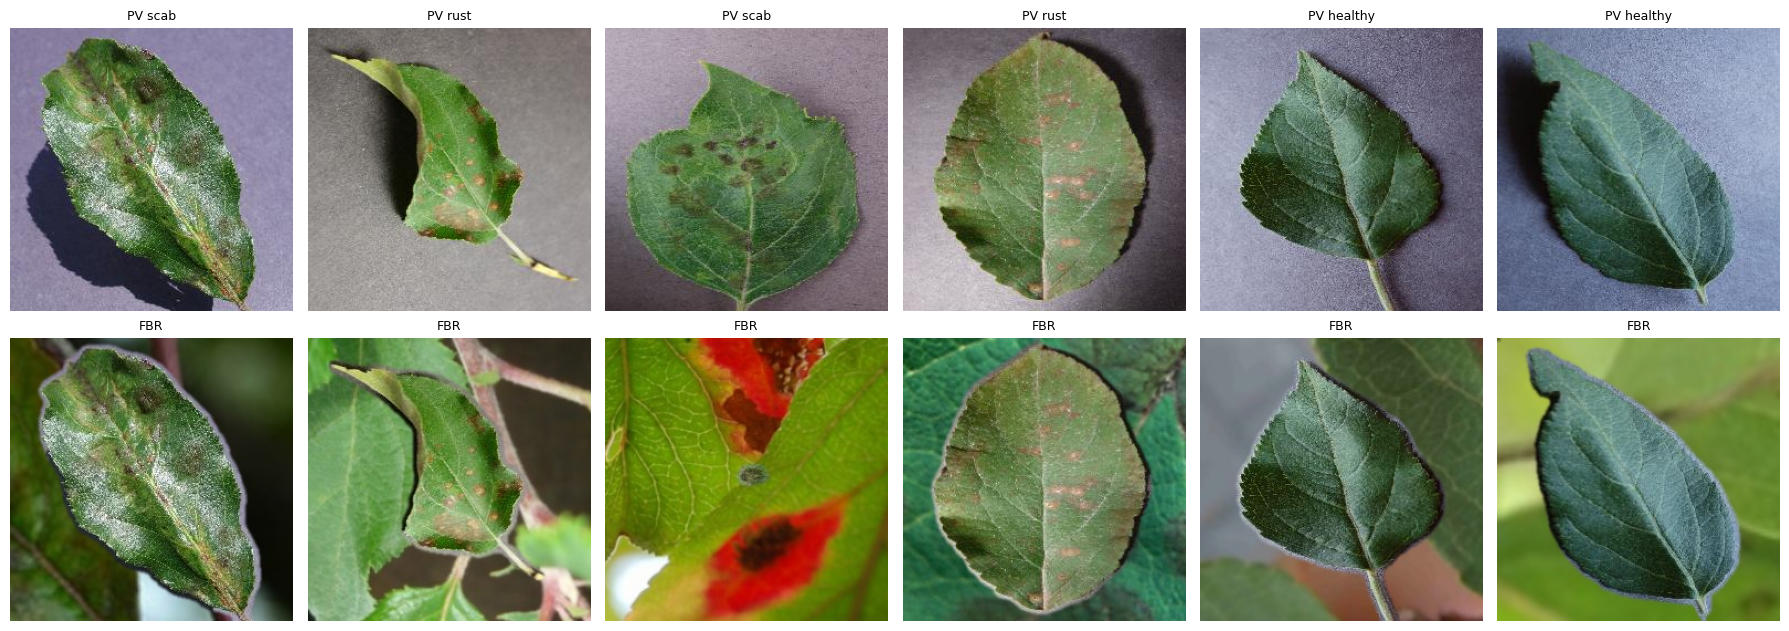

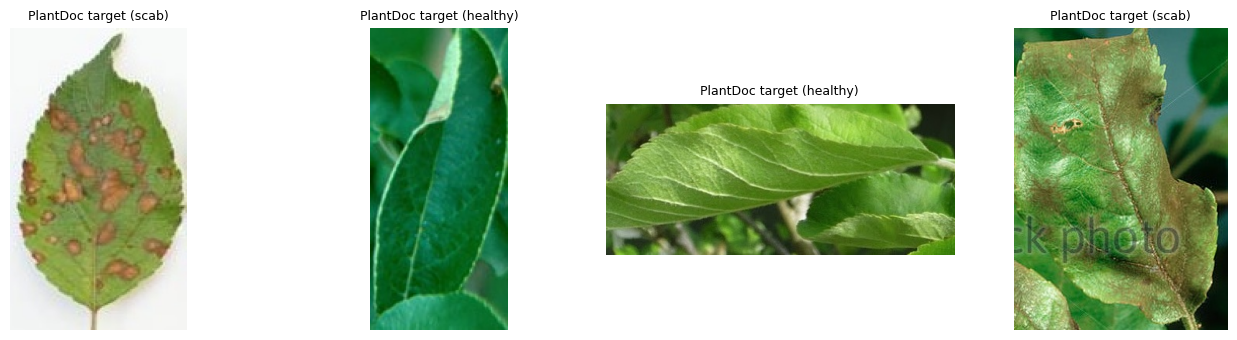

In [14]:
# ── Kiem tra bang mat: anh FBR co giong anh field khong? ──
_rng = random.Random(0)
n = 6
idxs = _rng.sample(range(len(fbr_samples)), n)
fig, axes = plt.subplots(2, n, figsize=(3 * n, 6.5))
for j, idx in enumerate(idxs):
    axes[0, j].imshow(Image.open(pvd_samples[idx][0]).convert('RGB'))
    axes[0, j].set_title(f'PV {CLASS_NAMES[pvd_samples[idx][1]]}', fontsize=9); axes[0, j].axis('off')
    axes[1, j].imshow(Image.open(fbr_samples[idx][0]).convert('RGB'))
    axes[1, j].set_title('FBR', fontsize=9); axes[1, j].axis('off')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for j, (p, l) in enumerate(_rng.sample(target_samples, 4)):
    axes[j].imshow(Image.open(p).convert('RGB'))
    axes[j].set_title(f'PlantDoc target ({CLASS_NAMES[l]})', fontsize=9); axes[j].axis('off')
plt.tight_layout(); plt.show()

### 4.1 — Loaders

- `SOURCE['fbr']` / `SOURCE['raw']`: cùng chỉ số train/val, chỉ khác ảnh (FBR hay gốc).
- `target_loader_3v`: `TargetThreeViewDataset` của notebook táo — trả `(plain, view1, view2)`;
  `plain` cho CDAN+E, hai view sinh trong `fork_rng` cho Mean Teacher. **Mọi** nhánh đều
  đọc loader này (kể cả nhánh không dùng target) để tiêu thụ RNG giống hệt nhau.

In [15]:
class TargetThreeViewDataset(Dataset):
    # Target khong nhan -> ((plain, view1, view2), -1).
    # plain: VAL_TRANSFORM, tat dinh. view1/view2: TRAIN_TRANSFORM sinh trong fork_rng,
    # seed theo (base_seed, epoch, idx) -> khong dung RNG toan cuc, tai lap duoc sau resume.
    def __init__(self, samples, plain_transform, aug_transform, base_seed):
        self.samples         = samples
        self.plain_transform = plain_transform
        self.aug_transform   = aug_transform
        self.base_seed       = base_seed
        self.epoch           = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, _ = self.samples[idx]
        img   = Image.open(path).convert('RGB')
        plain = self.plain_transform(img)
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed((self.base_seed * 1_000_003 + self.epoch * 10_007 + idx) % (2**31 - 1))
            v1 = self.aug_transform(img)
            v2 = self.aug_transform(img)
        return (plain, v1, v2), -1


def _source_loaders(samples):
    ds_tr = PlantDiseaseDataset(samples, CLASS_NAMES, TRAIN_TRANSFORM)
    ds_vl = PlantDiseaseDataset(samples, CLASS_NAMES, VAL_TRANSFORM)
    return (make_loader(Subset(ds_tr, src_tr_idx), BATCH_SIZE, shuffle=True, drop_last=True),
            make_loader(Subset(ds_vl, src_vl_idx), BATCH_SIZE, shuffle=False))

SOURCE = {'fbr': _source_loaders(fbr_samples), 'raw': _source_loaders(pvd_samples)}

dataset_tgt_3v   = TargetThreeViewDataset(target_samples, VAL_TRANSFORM, TRAIN_TRANSFORM, DATA_SEED)
target_loader_3v = make_loader(dataset_tgt_3v, BATCH_SIZE, shuffle=True, drop_last=True)
test_loader      = make_loader(PlantDiseaseDataset(test_samples, CLASS_NAMES, VAL_TRANSFORM),
                               BATCH_SIZE, shuffle=False)

assert len(target_loader_3v) >= 1, (
    f'Target {len(target_samples)} anh < BATCH_SIZE {BATCH_SIZE} -> giam BATCH_SIZE')

# ── Kiem tra tai cho (giong notebook tao) ───────────────────────────────────
(_p, _v1, _v2), _l = next(iter(target_loader_3v))
assert _p.shape == _v1.shape == _v2.shape == (BATCH_SIZE, 3, 224, 224)
assert not torch.allclose(_v1, _v2), 'view1 == view2 -> L_cons luon = 0'
assert not torch.allclose(_p, _v1), 'plain dang bi augment'
assert (_l == -1).all(), 'target loader tra ve nhan that'

torch.manual_seed(123); _before = torch.rand(3)
torch.manual_seed(123); dataset_tgt_3v.set_epoch(7); _ = dataset_tgt_3v[0]; _after = torch.rand(3)
assert torch.equal(_before, _after), 'fork_rng ro ri sang RNG toan cuc'
del _p, _v1, _v2, _l, _before, _after

print(f'source train: {len(SOURCE["fbr"][0])} batch/epoch | '
      f'target: {len(target_loader_3v)} batch/luot (lap lai khi het) | '
      f'test: {len(test_samples)} anh')

source train: 20 batch/epoch | target: 15 batch/luot (lap lai khi het) | test: 511 anh


## 5 — Models, CDAN+E & Mean Teacher helpers (giống notebook táo)

In [16]:
def get_lambda(step, max_steps, gamma=10.0):
    p = step / max_steps
    return 2.0 / (1.0 + np.exp(-gamma * p)) - 1.0


def domain_lbl(n, is_src, device):
    return torch.full((n,), 0 if is_src else 1, dtype=torch.long, device=device)


class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x.clone()

    @staticmethod
    def backward(ctx, grad):
        return -ctx.lam * grad, None


class GradRevLayer(nn.Module):
    def __init__(self, lam=1.0):
        super().__init__()
        self.lam = lam
    def forward(self, x):
        return GRL.apply(x, self.lam)
    def set_lam(self, lam):
        self.lam = lam


class FeatureExtractor(nn.Module):
    # ResNet ImageNet, bo FC. BACKBONE (§2): resnet18 -> 512-d, resnet50 -> 2048-d (weights nhu notebook B).
    def __init__(self, pretrained=True, backbone=BACKBONE):
        super().__init__()
        if backbone == 'resnet18':
            net = tv_models.resnet18(weights=tv_models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
            self.out_dim = 512
        elif backbone == 'resnet50':
            net = tv_models.resnet50(weights=tv_models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
            self.out_dim = 2048
        else:
            raise ValueError(f'unknown backbone: {backbone}')
        self.net = nn.Sequential(*list(net.children())[:-1])
    def forward(self, x):
        return self.net(x).flatten(1)


class Classifier(nn.Module):
    def __init__(self, in_dim=512, num_classes=NUM_CLASSES):
        super().__init__()
        self.fc = nn.Linear(in_dim, num_classes)
    def forward(self, x):
        return self.fc(x)


class CDANDisc(nn.Module):
    # Input = multilinear map, dim = 512 * num_classes. Hai lop an 512, 256.
    def __init__(self, in_dim=512, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim * num_classes, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 2),
        )
    def forward(self, x):
        return self.net(x)


def multilinear_map(feat, pred):
    # KHONG detach feat: gradient doi khang phai qua GRL toi phi.
    return torch.bmm(feat.unsqueeze(2), pred.unsqueeze(1)).view(feat.size(0), -1)


def cdan_entropy_weight(probs):
    # w = 1 + exp(-H(p)); detach -> chi la he so.
    ent = -(probs * torch.log(probs + 1e-5)).sum(dim=1)
    return (1.0 + torch.exp(-ent)).detach()


# ── Mean Teacher ─────────────────────────────────────────────────────────────
EMA_DECAY     = 0.99
CONS_MAX      = float(NUM_CLASSES ** 2)   # = C^2 (notebook tao: 9 voi C=3)
CONS_START    = 100
CONS_RAMP_LEN = 50


def sigmoid_rampup(x, length):
    if length == 0:
        return 1.0
    x = float(np.clip(x, 0.0, length)) / length
    return float(np.exp(-5.0 * (1.0 - x) ** 2))


def consistency_weight(epoch, cons_max=CONS_MAX, start=CONS_START, ramp_len=CONS_RAMP_LEN):
    return 0.0 if epoch < start else cons_max * sigmoid_rampup(epoch - start, ramp_len)


def softmax_mse_loss(input_logits, target_logits):
    # Tong tren batch / num_classes; cho goi chia them batch size.
    return F.mse_loss(F.softmax(input_logits, 1), F.softmax(target_logits, 1),
                      reduction='sum') / input_logits.size(1)


def create_teacher(student_phi, student_G, device):
    phi_t = FeatureExtractor(pretrained=False).to(device)
    G_t   = Classifier(phi_t.out_dim, NUM_CLASSES).to(device)
    phi_t.load_state_dict(student_phi.state_dict())
    G_t.load_state_dict(student_G.state_dict())
    for p in list(phi_t.parameters()) + list(G_t.parameters()):
        p.requires_grad_(False)
    return phi_t, G_t


def update_ema(student_mods, teacher_mods, global_step, ema_decay=EMA_DECAY):
    # Chi .parameters(); BN buffer cua teacher cap nhat qua forward o .train().
    alpha = min(1 - 1 / (global_step + 1), ema_decay)
    with torch.no_grad():
        for sm, tm in zip(student_mods, teacher_mods):
            for ema_p, p in zip(tm.parameters(), sm.parameters()):
                ema_p.data.mul_(alpha).add_(p.data, alpha=1 - alpha)


# ── Danh gia: tong, theo lop, macro, confusion ──────────────────────────────
def evaluate(phi, G, loader, device):
    phi.eval(); G.eval()
    cm = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=int)   # [true, pred]
    with torch.no_grad():
        for imgs, lbls in loader:
            preds = G(phi(imgs.to(device))).argmax(1).cpu().numpy()
            for t, p in zip(lbls.numpy(), preds):
                cm[t, p] += 1
    per_class = {c: (100.0 * cm[i, i] / cm[i].sum() if cm[i].sum() else float('nan'))
                 for i, c in enumerate(CLASS_NAMES)}
    return {
        'acc': 100.0 * np.trace(cm) / cm.sum(),
        'macro_acc': float(np.nanmean(list(per_class.values()))),
        'per_class': per_class,
        'confusion': cm.tolist(),
    }

print(f'Models & helpers defined. NUM_CLASSES={NUM_CLASSES}, CONS_MAX={CONS_MAX}')

Models & helpers defined. NUM_CLASSES=3, CONS_MAX=9.0


## 6 — Một vòng lặp cho cả 5 nhánh

`train_arm(arm, seed)` là vòng lặp `train_cdane` của notebook táo, tổng quát hoá bằng
hai cờ `use_cdan` / `use_mt`. Giữ nguyên bốn điểm ghép cặp RNG:

1. Thứ tự khởi tạo `FeatureExtractor → Classifier → CDANDisc` ở **mọi** nhánh
   (nhánh không dùng D vẫn khởi tạo nó để tiêu thụ RNG giống nhau).
2. Teacher dựng trong `fork_rng` ở mọi nhánh.
3. `g.manual_seed(seed*1000 + epoch)` mỗi epoch.
4. View của target sinh trong `fork_rng`, seed theo `(DATA_SEED, epoch, lượt)`.

**Thay đổi duy nhất về cấu trúc:** một epoch = một lượt qua **source**
(~14 batch). Target chỉ có ~3 batch nên được lặp lại khi hết; mỗi lượt lặp gọi
`set_epoch(epoch*100 + lượt)` để hai view không lặp lại y hệt trong cùng epoch.

Chọn model: `val_loss` trên source val, từ epoch `MIN_SEL` — đo bằng **student** cho
nhánh không có MT, **teacher (EMA)** cho nhánh có MT (giống notebook táo).

`probe_epochs=N` chạy **đúng vòng lặp này** nhưng bỏ forward/backward, chỉ ghi chữ ký
batch source — đó là cách cell `rng_probe` kiểm chứng ghép cặp mà không cần code riêng.

In [17]:
ARMS = {
    #  arm        : (source, use_cdan, use_mt, ten hien thi)
    'src_raw'  : ('raw', False, False, 'Source-only (PV goc, no FBR)'),
    'src_fbr'  : ('fbr', False, False, 'Source-only w/ FBR'),
    'cdane'    : ('fbr', True,  False, 'CDAN+E w/ FBR'),
    'mt_only'  : ('fbr', False, True,  'MT only w/ FBR'),
    'cdane_mt' : ('fbr', True,  True,  'CDAN+E + MT w/ FBR'),
}
PAIRED_ARMS = ['src_fbr', 'cdane', 'mt_only', 'cdane_mt']   # cung source FBR -> phai cung dong RNG


def _target_batches(epoch):
    # Lap target loader cho du so batch cua source. Moi luot moi -> view moi.
    n_pass = 0
    while True:
        dataset_tgt_3v.set_epoch(epoch * 100 + n_pass)
        for batch in target_loader_3v:
            yield batch
        n_pass += 1


def save_ckpt(path, epoch, step, best_loss, best_state, phi, G, D, opt, sch, phi_t, G_t):
    torch.save({'epoch': epoch, 'step': step, 'best_loss': best_loss, 'best_state': best_state,
                'phi': phi.state_dict(), 'G': G.state_dict(), 'D': D.state_dict(),
                'optimizer': opt.state_dict(), 'scheduler': sch.state_dict(),
                # state_dict cua teacher gom ca BN buffer -> bat buoc luu de resume dung.
                'phi_t': phi_t.state_dict(), 'G_t': G_t.state_dict()}, path)


def load_ckpt(path, phi, G, D, opt, sch, phi_t, G_t):
    if not os.path.exists(path):
        return 1, 0, float('inf'), None
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    phi.load_state_dict(ck['phi']); G.load_state_dict(ck['G']); D.load_state_dict(ck['D'])
    opt.load_state_dict(ck['optimizer']); sch.load_state_dict(ck['scheduler'])
    phi_t.load_state_dict(ck['phi_t']); G_t.load_state_dict(ck['G_t'])
    return ck['epoch'] + 1, ck['step'], ck['best_loss'], ck['best_state']


def train_arm(arm, seed, max_epochs=MAX_EPOCHS, min_sel=MIN_SEL, ckpt_dir=CKPT_DIR,
              log_every=LOG_EVERY, probe_epochs=None, verbose=True):
    src_key, use_cdan, use_mt, _ = ARMS[arm]
    train_loader_src, val_loader_src = SOURCE[src_key]
    set_seed(seed)

    # (1) Thu tu khoi tao giong nhau o moi nhanh.
    phi = FeatureExtractor(pretrained=True).to(DEVICE)
    G   = Classifier(phi.out_dim, NUM_CLASSES).to(DEVICE)
    D   = CDANDisc(phi.out_dim, NUM_CLASSES).to(DEVICE)
    grl = GradRevLayer()
    # (2) Teacher trong fork_rng.
    with torch.random.fork_rng(devices=[]):
        phi_t, G_t = create_teacher(phi, G, DEVICE)

    params = list(phi.parameters()) + list(G.parameters()) + (list(D.parameters()) if use_cdan else [])
    opt = optim.AdamW(params, lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    ce_mean, ce_persam = nn.CrossEntropyLoss(), nn.CrossEntropyLoss(reduction='none')

    n_epochs = probe_epochs or max_epochs
    ckpt_path = best_path = None
    start_epoch, step, best_loss, best_state = 1, 0, float('inf'), None
    if ckpt_dir is not None and probe_epochs is None:
        ckpt_path = os.path.join(ckpt_dir, f'{arm}_s{seed}_ckpt.pth')
        best_path = os.path.join(ckpt_dir, f'{arm}_s{seed}_best.pth')
        start_epoch, step, best_loss, best_state = load_ckpt(
            ckpt_path, phi, G, D, opt, sch, phi_t, G_t)
        if start_epoch > 1 and verbose:
            print(f'  [resume] {arm} s{seed}: tiep tuc tu epoch {start_epoch}')

    steps_per_epoch = len(train_loader_src)
    total_steps     = max_epochs * steps_per_epoch
    sel_phi, sel_G  = (phi_t, G_t) if use_mt else (phi, G)
    collapse_share  = 100 * (0.5 + 0.5 / NUM_CLASSES)
    sigs, lam       = [], 0.0

    for epoch in range(start_epoch, n_epochs + 1):
        g.manual_seed(seed * 1000 + epoch)                    # (3)
        tgt_iter = _target_batches(epoch)                     # (4) ben trong
        phi.train(); G.train(); D.train()
        phi_t.train(); G_t.train()                            # BN buffer cua teacher
        w_cons = consistency_weight(epoch) if use_mt else 0.0
        ep = {'cls': 0.0, 'cdan': 0.0, 'cons': 0.0}
        tgt_hist = torch.zeros(NUM_CLASSES, dtype=torch.long)

        for si, sl in train_loader_src:
            (t_plain, t_v1, t_v2), _ = next(tgt_iter)        # moi nhanh deu doc target
            if probe_epochs is not None:
                sigs.append((round(float(si.sum()), 4), int(sl.sum())))
                continue

            si, sl = si.to(DEVICE), sl.to(DEVICE)
            lam = get_lambda(step, total_steps); grl.set_lam(lam)
            step += 1
            opt.zero_grad()

            sf = phi(si)
            logits_s = G(sf)
            L_cls = ce_mean(logits_s, sl)
            total = L_cls

            if use_cdan:
                t_plain = t_plain.to(DEVICE)
                tf = phi(t_plain)
                logits_t = G(tf)
                sp, tp = torch.softmax(logits_s, 1), torch.softmax(logits_t, 1)
                src_mm = grl(multilinear_map(sf, sp.detach()))
                tgt_mm = grl(multilinear_map(tf, tp.detach()))
                sw = cdan_entropy_weight(sp); sw = sw / sw.sum()
                tw = cdan_entropy_weight(tp); tw = tw / tw.sum()
                src_d = (sw * ce_persam(D(src_mm), domain_lbl(si.size(0), True, DEVICE))).sum()
                tgt_d = (tw * ce_persam(D(tgt_mm), domain_lbl(t_plain.size(0), False, DEVICE))).sum()
                L_cdan = (src_d + tgt_d) / 2.0
                total = total + L_cdan
                ep['cdan'] += L_cdan.item()
                probe = logits_t.detach()

            if use_mt:
                t_v1, t_v2 = t_v1.to(DEVICE), t_v2.to(DEVICE)
                student_logits = G(phi(t_v1))
                with torch.no_grad():
                    teacher_logits = G_t(phi_t(t_v2))
                L_cons = softmax_mse_loss(student_logits, teacher_logits) / t_v1.size(0)
                total = total + w_cons * L_cons
                ep['cons'] += L_cons.item()
                probe = teacher_logits

            if use_cdan or use_mt:
                tgt_hist += torch.bincount(probe.argmax(1).cpu(), minlength=NUM_CLASSES)

            total.backward()
            opt.step()
            if use_mt:
                update_ema([phi, G], [phi_t, G_t], step)
            ep['cls'] += L_cls.item()

        if probe_epochs is not None:
            continue
        sch.step()

        # Validation tren source val (khong dung nhan target).
        sel_phi.eval(); sel_G.eval()
        vl, vc, vt = 0.0, 0, 0
        with torch.no_grad():
            for vi, vlab in val_loader_src:
                vi, vlab = vi.to(DEVICE), vlab.to(DEVICE)
                logits = sel_G(sel_phi(vi))
                vl += ce_mean(logits, vlab).item()
                vc += (logits.argmax(1) == vlab).sum().item()
                vt += vlab.size(0)
        val_loss, val_acc = vl / len(val_loader_src), vc / vt

        if epoch >= min_sel and val_loss < best_loss:
            best_loss  = val_loss
            best_state = {'phi': copy.deepcopy(sel_phi.state_dict()),
                          'G':   copy.deepcopy(sel_G.state_dict())}
            if best_path:
                torch.save(best_state, best_path)

        if verbose and (epoch % log_every == 0 or epoch == max_epochs):
            msg = (f'  [{arm} s{seed}] ep {epoch:03d}/{max_epochs} val_acc={val_acc*100:5.1f}% '
                   f'lam={lam:.3f} w={w_cons:.2f} | cls={ep["cls"]/steps_per_epoch:.3f} '
                   f'cdan={ep["cdan"]/steps_per_epoch:.3f} cons={ep["cons"]/steps_per_epoch:.4f}')
            if tgt_hist.sum() > 0:
                share = tgt_hist.float() / tgt_hist.sum() * 100
                msg += ' | tgt%=[' + ','.join(f'{s:.0f}' for s in share) + ']'
                if share.max().item() > collapse_share:
                    msg += f'\n     CANH BAO: target du doan don ve 1 lop ({share.max():.0f}%)'
            print(msg)

        if ckpt_path and (epoch % log_every == 0 or epoch == max_epochs):
            save_ckpt(ckpt_path, epoch, step, best_loss, best_state, phi, G, D, opt, sch, phi_t, G_t)

    if probe_epochs is not None:
        return sigs

    if best_state is None:
        print(f'  CANH BAO [{arm}]: chua toi cua so chon model, dung weight cuoi.')
        best_state = {'phi': copy.deepcopy(sel_phi.state_dict()), 'G': copy.deepcopy(sel_G.state_dict())}

    eval_phi = FeatureExtractor(pretrained=False).to(DEVICE)
    eval_G   = Classifier(eval_phi.out_dim, NUM_CLASSES).to(DEVICE)
    eval_phi.load_state_dict(best_state['phi']); eval_G.load_state_dict(best_state['G'])

    res = evaluate(eval_phi, eval_G, test_loader, DEVICE)
    res.update({'arm': arm, 'seed': seed, 'data_seed': DATA_SEED, 'task': TASK,
                'protocol': PROTOCOL, 'backbone': BACKBONE, 'n_test': len(test_samples),
                'best_val_loss': best_loss, 'epochs_run': max_epochs,
                'acc_student_final': evaluate(phi, G, test_loader, DEVICE)['acc']})
    if use_mt and res['acc_student_final'] > res['acc'] + 3.0:
        print(f'  CANH BAO: student ({res["acc_student_final"]:.2f}%) hon han teacher '
              f'({res["acc"]:.2f}%) - nghi ngo BN buffer chua sync')
    return res

print('train_arm() defined. Arms:', list(ARMS))

train_arm() defined. Arms: ['src_raw', 'src_fbr', 'cdane', 'mt_only', 'cdane_mt']


## 7 — Kiểm chứng ghép cặp RNG (chạy trước, vài phút, không huấn luyện)

Bốn nhánh dùng source FBR phải thấy **cùng** chuỗi ảnh source (cùng thứ tự, cùng
augmentation). `[FAIL]` nghĩa là chênh lệch accuracy giữa các nhánh không còn quy được
về loss — đừng chạy 300 epoch.

In [18]:
_ref = train_arm(PAIRED_ARMS[0], SEEDS[0], probe_epochs=2, verbose=False)
print(f'So batch source doi chieu: {len(_ref)}')
for _arm in PAIRED_ARMS[1:]:
    _sig = train_arm(_arm, SEEDS[0], probe_epochs=2, verbose=False)
    if _sig == _ref:
        print(f'  [OK]   {PAIRED_ARMS[0]} == {_arm}')
    else:
        _i = next(i for i, (a, b) in enumerate(zip(_ref, _sig)) if a != b)
        print(f'  [FAIL] {PAIRED_ARMS[0]} vs {_arm}: lech tu batch {_i}: {_ref[_i]} vs {_sig[_i]}')
    assert _sig == _ref, f'{_arm} KHONG ghep cap voi {PAIRED_ARMS[0]} - dung chay tiep.'
del _ref, _sig

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 239MB/s]


So batch source doi chieu: 40
  [OK]   src_fbr == cdane
  [OK]   src_fbr == mt_only
  [OK]   src_fbr == cdane_mt


## 8 — Chạy tất cả nhánh × seed

Mỗi `(nhánh, seed)` ghi một file JSON trong `RESULTS_DIR`; đã có thì bỏ qua (xoá file
để chạy lại). Colab ngắt giữa chừng thì chạy lại cell này — checkpoint mỗi
`LOG_EVERY` epoch, tự resume.

Muốn chạy bớt nhánh, sửa `RUN_ARMS`. Thời gian tham khảo trên T4: nhánh `src_*` nhanh
nhất, `cdane_mt` chậm nhất (4 forward pass / iteration).

In [19]:
# src_raw = dong doi chieu voi 'Baseline (w/o DA)' cua MSUN (khong thich nghi, khong FBR).
RUN_ARMS = ['cdane_mt']   # du ablation: list(ARMS)


def result_path(arm, seed):
    return os.path.join(RESULTS_DIR, f'{arm}_s{seed}.json')


for seed in SEEDS:
    for arm in RUN_ARMS:
        path = result_path(arm, seed)
        if os.path.exists(path):
            print(f'[skip] {os.path.basename(path)} da co')
            continue
        print('=' * 64)
        print(f'ARM: {ARMS[arm][3]}  (seed={seed}, task={TASK})')
        print('=' * 64)
        res = train_arm(arm, seed)
        with open(path, 'w') as f:
            json.dump(res, f, indent=2)
        pc = ', '.join(f'{c}={v:.2f}%' for c, v in res['per_class'].items())
        print(f'-> test PlantDoc: acc={res["acc"]:.2f}%  macro={res["macro_acc"]:.2f}%  ({pc})')

ARM: CDAN+E + MT w/ FBR  (seed=42, task=apple_cpd)
  [cdane_mt s42] ep 010/300 val_acc= 97.7% lam=0.164 w=0.00 | cls=0.093 cdan=0.604 cons=0.0722 | tgt%=[35,30,35]
  [cdane_mt s42] ep 020/300 val_acc= 97.3% lam=0.321 w=0.00 | cls=0.038 cdan=0.662 cons=0.0752 | tgt%=[37,28,35]
  [cdane_mt s42] ep 030/300 val_acc= 97.7% lam=0.461 w=0.00 | cls=0.082 cdan=0.666 cons=0.0669 | tgt%=[32,27,40]
  [cdane_mt s42] ep 040/300 val_acc= 99.1% lam=0.582 w=0.00 | cls=0.045 cdan=0.677 cons=0.0632 | tgt%=[35,29,36]
  [cdane_mt s42] ep 050/300 val_acc= 98.2% lam=0.682 w=0.00 | cls=0.016 cdan=0.658 cons=0.0687 | tgt%=[39,25,36]
  [cdane_mt s42] ep 060/300 val_acc= 97.7% lam=0.761 w=0.00 | cls=0.211 cdan=0.678 cons=0.0818 | tgt%=[38,26,37]
  [cdane_mt s42] ep 070/300 val_acc= 98.2% lam=0.823 w=0.00 | cls=0.015 cdan=0.666 cons=0.0683 | tgt%=[38,27,35]
  [cdane_mt s42] ep 080/300 val_acc= 96.3% lam=0.870 w=0.00 | cls=0.066 cdan=0.688 cons=0.0564 | tgt%=[37,30,33]
  [cdane_mt s42] ep 090/300 val_acc= 97.7% la

## 9 — So sánh

Bảng 1: các nhánh của ta (mean ± std qua seed). Bảng 2: chênh lệch **ghép cặp** giữa các nhánh. Bảng 3: đặt cạnh cột Apple của
MSUN Table 5. Accuracy của ta là accuracy tổng trên mọi crop táo của tập test, cùng định nghĩa với cột Apple
("độ chính xác trên ảnh táo"), nhưng **khác số lớp** (3 so với 27).


In [20]:
# === CELL-TAG: compare ===
_rows = {}
for arm in ARMS:
    rs = [json.load(open(result_path(arm, s))) for s in SEEDS if os.path.exists(result_path(arm, s))]
    if rs:
        _rows[arm] = rs

if not _rows:
    print('Chua co ket qua nao. Chay cell muc 8 truoc.')
else:
    def _ms(vals):
        return f'{np.mean(vals):6.2f}' + (f' ± {np.std(vals, ddof=1):5.2f}' if len(vals) > 1 else '        ')

    cols = ['acc', 'macro_acc'] + CLASS_NAMES
    w = 18
    print(f'BANG 1 - cac nhanh ({PROTOCOL}, {BACKBONE}, test = {len(test_samples)} crop tao)')
    print('=' * (36 + w * len(cols)))
    print(f'{"Method":<30}{"n":>4}  ' + ''.join(f'{c:>{w}}' for c in cols))
    print('-' * (36 + w * len(cols)))
    for arm, rs in _rows.items():
        vals = [_ms([r['acc'] for r in rs]), _ms([r['macro_acc'] for r in rs])]
        vals += [_ms([r['per_class'][c] for r in rs]) for c in CLASS_NAMES]
        print(f'{ARMS[arm][3]:<30}{len(rs):>4}  ' + ''.join(f'{v:>{w}}' for v in vals))
    print('=' * (36 + w * len(cols)))

    # ── Chenh lech ghep cap (cung seed) ─────────────────────────────────────
    PAIRS = [('src_fbr', 'src_raw', 'FBR'),
             ('cdane', 'src_fbr', 'CDAN+E (tren FBR)'),
             ('mt_only', 'src_fbr', 'MT (tren FBR)'),
             ('cdane_mt', 'cdane', 'them MT vao CDAN+E'),
             ('cdane_mt', 'mt_only', 'them CDAN+E vao MT')]
    print('\nBANG 2 - CHENH LECH GHEP CAP (cung seed), don vi: diem %')
    print('-' * 72)
    for a, b, label in PAIRS:
        if a in _rows and b in _rows:
            ra = {r['seed']: r for r in _rows[a]}
            rb = {r['seed']: r for r in _rows[b]}
            common = sorted(set(ra) & set(rb))
            if not common:
                continue
            d_acc   = [ra[s]['acc'] - rb[s]['acc'] for s in common]
            d_macro = [ra[s]['macro_acc'] - rb[s]['macro_acc'] for s in common]
            print(f'  {label:<22} {a:>9} - {b:<8}: acc {_ms(d_acc)} | macro {_ms(d_macro)}  (n={len(common)})')

    # ── Dat canh MSUN Table 5, cot Apple ─────────────────────────────────────
    print(f'\nBANG 3 - DAT CANH MSUN TABLE 5, COT APPLE (accuracy % tren anh tao cua C-PD)')
    print('-' * 72)
    for m, v in MSUN_TABLE5_APPLE.items():
        print(f'  {m + " [MSUN, 27 lop]":<40}{v:>8.2f}')
    print('-' * 72)
    for arm, rs in _rows.items():
        print(f'  {ARMS[arm][3] + " [ours, 3 lop]":<40}{np.mean([r["acc"] for r in rs]):>8.2f}')
    print('-' * 72)
    print(f'  C-PD tao: MSUN {sum(MSUN_CPD_COUNTS.values())} crop '
          f'({", ".join(f"{c}={n}" for c, n in MSUN_CPD_COUNTS.items())}); '
          f'ours {len(cpd_final)} crop ({_count(to_samples(cpd_final))}).')
    print('  Dong doi chieu cong bang nhat: src_raw (khong thich nghi) vs "Baseline (w/o DA)".')

    # ── Confusion matrix cua seed dau tien ──────────────────────────────────
    print(f'\nCONFUSION MATRIX (seed {SEEDS[0]}, hang = nhan that, cot = du doan; thu tu {CLASS_NAMES})')
    for arm, rs in _rows.items():
        r0 = next((r for r in rs if r['seed'] == SEEDS[0]), rs[0])
        print(f'  {ARMS[arm][3]:<26} {r0["confusion"]}')


BANG 1 - cac nhanh (transductive, resnet50, test = 511 crop tao)
Method                           n                 acc         macro_acc           healthy              rust              scab
------------------------------------------------------------------------------------------------------------------------------
CDAN+E + MT w/ FBR               1       80.23             81.74             74.06             91.30             79.85        

BANG 2 - CHENH LECH GHEP CAP (cung seed), don vi: diem %
------------------------------------------------------------------------

BANG 3 - DAT CANH MSUN TABLE 5, COT APPLE (accuracy % tren anh tao cua C-PD)
------------------------------------------------------------------------
  Baseline (w/o DA) [MSUN, 27 lop]           67.38
  DAAN [MSUN, 27 lop]                        68.64
  D-Coral [MSUN, 27 lop]                     69.06
  DAN [MSUN, 27 lop]                         70.29
  DANN [MSUN, 27 lop]                        69.63
  MRAN [MSUN, 27 

### Cách phát biểu kết quả trong luận văn

1. **So với MSUN là so lỏng, và lệch về phía có lợi cho ta.** Cùng cặp PVD → C-PD, cùng backbone ResNet-50, cùng đánh giá
   transductive. Nhưng MSUN phân loại **27 lớp**, ta chỉ 3, nên một lá táo của MSUN có thể bị nhầm sang lớp của cây khác. Phát
   biểu: *"Trên phần táo của C-PD, MSUN đạt 71.45% trong bài toán 27 lớp; pipeline của chúng tôi đạt X% trong bài toán 3 lớp
   táo"*, không phát biểu *"vượt MSUN"*.
2. **C-PD là bản tái tạo.** Ghi số crop sau khi lọc tay (in ở §3.4) cạnh 241 / 138 / 134 của MSUN, và mô tả tiêu chí lọc.
3. **Source khác.** MSUN dùng 20% PVD (táo 397 / 219 / 251, lệch về healthy); ta dùng 300 / 275 / 300 cân bằng, vì notebook C
   cho thấy source lệch lớp làm pipeline sụp lớp rust.
4. **Kết luận về từng thành phần dùng bảng ghép cặp** (Bảng 2), không dùng bảng mean ± std.
5. **Target chỉ vài trăm ảnh.** Với `n=1` seed, chênh lệch vài điểm chưa kết luận được; nên chạy `SEEDS = [42, 43, 44]`.
6. Theo dõi dòng `tgt%` trong log: PlantDoc khó hơn Plant Pathology nhiều, nên sụp về
   một lớp là rủi ro thật.
